In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import importlib

from pathlib import Path
from scipy.interpolate import PchipInterpolator

# ============================================================
# IMPORT YOUR PYTHON MODULE



# ============================================================
# IMPORT AND RELOAD RATING CURVE FUNCTIONS
# ============================================================

import importlib
import rating_curve_DISCHARGE_STAGE_PROBABILITY as rc

# Reload after editing Python file
importlib.reload(rc)

# Import functions
from rating_curve_DISCHARGE_STAGE_PROBABILITY import (
    predict_exceedance_probability,
    discharge_at_return_period,
    create_stage_probability_table,
    load_watershed_data
)

print("Rating curve functions loaded successfully!")


Rating curve functions loaded successfully!


In [2]:
script_dir = Path.cwd()

data_dir = script_dir / "SAVE_DATA"

rating_dir = data_dir / "OBSERVED-rating-curves-results"

rating_curve_files = {
    "Hanalei": {
        "rating_file": "Hanalei_observed_rating_curve_model.csv",
        "probability_column": "Hanalei_weighted"
    },

    "Waiahole": {
        "rating_file": "Waiahole_observed_rating_curve_model.csv",
        "probability_column": "Waiahole_weighted"
    },

    "Waialua": {
        "rating_file": "waialua-datum-adjusted_observed_rating_curve_model.csv",
        "probability_column": "Waialua_weighted"
    }
}

probability_file = (
    data_dir / "Peak_Fq_USGS_probability.csv"
)

In [3]:

# ============================================================
# WATERSHED CONFIGURATION
# ============================================================



watershed_data = load_watershed_data(
    rating_dir=rating_dir,
    probability_file=probability_file,
    watershed_files=rating_curve_files
)

# ============================================================
# CREATE CONVENIENT INDIVIDUAL VARIABLES
# ============================================================

hanalei_data = watershed_data["Hanalei"]
waiahole_data = watershed_data["Waiahole"]
waialua_data = watershed_data["Waialua"]

# ============================================================
# SUMMARY TABLE
# ============================================================

summary = []

for watershed, data in watershed_data.items():

    rating = data["rating_curve"]
    probability = data["probability"]

    summary.append({
        "watershed": watershed,
        "rating_points": len(rating),
        "probability_points": len(probability),
        "min_stage_ft": rating["stage_ft"].min(),
        "max_stage_ft": rating["stage_ft"].max(),
        "max_rating_discharge_cfs": rating["median_cfs"].max(),
        "min_return_period_years": probability["return_period_years"].min(),
        "max_return_period_years": probability["return_period_years"].max()
    })

watershed_summary = pd.DataFrame(summary)

display(watershed_summary)

# ============================================================
# EXAMPLE: ACCESS INDIVIDUAL DATA
# ============================================================

print("\nWAIALUA RATING CURVE")
display(watershed_data["Waialua"]["rating_curve"].head())

print("\nWAIALUA PROBABILITY")
display(watershed_data["Waialua"]["probability"].head())

Hanalei: 1000 rating points, 25 probability points
Waiahole: 1000 rating points, 25 probability points
Waialua: 1000 rating points, 25 probability points


,watershed,rating_points,probability_points,min_stage_ft,max_stage_ft,max_rating_discharge_cfs,min_return_period_years,max_return_period_years
0,Hanalei,1000,25,4.780282,100.0,2.107159e+05,1.005025,500.0
1,Waiahole,1000,25,4.123036,100.0,6.067753e+05,1.005025,500.0
2,Waialua,1000,25,12.418143,100.0,1.513085e+06,1.005025,500.0



WAIALUA RATING CURVE


,stage_ft,lower_cfs,median_cfs,upper_cfs
0,12.418143,0.0,0.000000,70.079361
1,12.505813,0.0,0.000000,74.509083
2,12.593482,0.0,0.879920,78.076880
3,12.681152,0.0,2.624951,82.253619
4,12.768821,0.0,4.770629,90.705390



WAIALUA PROBABILITY


,EXC_Prob,discharge_cfs,return_period_years
0,0.995,153.2,1.005025
1,0.990,201.9,1.010101
2,0.980,271.9,1.020408
3,0.975,301.0,1.025641
4,0.960,377.0,1.041667



HANALEI
1000-year discharge: 48,743.4 cfs
First crossing stage: 22 ft
Final cutoff stage: 23 ft
Number of 1-ft stages: 19


,stage_ft,stage_m,median_cfs,median_cms,lower_cfs,upper_cfs,EXC_Prob,return_period_years
0,5,1.5240,0.000000,0.000000,0.000000,9022.214240,1.000000,1.000000
1,6,1.8288,4192.183909,118.709429,0.000000,11523.620360,1.000000,1.000000
2,7,2.1336,7516.072905,212.831483,3835.071529,14549.171158,0.953288,1.049001
3,8,2.4384,10208.110953,289.061512,5756.605435,18010.312117,0.852248,1.173368
4,9,2.7432,12785.262388,362.038314,7541.495939,22313.191163,0.711417,1.405645
5,10,3.0480,15293.018180,433.050050,9089.496420,26612.934334,0.559346,1.787801
6,11,3.3528,18032.110831,510.612516,10436.426344,30610.820999,0.404108,2.474583
7,12,3.6576,20489.880485,580.208802,12246.806618,34614.741997,0.287655,3.476389
8,13,3.9624,23524.656565,666.144091,13880.579535,39644.957405,0.179943,5.557308
9,14,4.2672,26646.804685,754.553480,15365.407550,47012.784020,0.105698,9.460927



WAIAHOLE
1000-year discharge: 21,747.8 cfs
First crossing stage: 21 ft
Final cutoff stage: 22 ft
Number of 1-ft stages: 18


,stage_ft,stage_m,median_cfs,median_cms,lower_cfs,upper_cfs,EXC_Prob,return_period_years
0,5,1.5240,204.224582,5.782996,0.000000,1248.154997,1.000000,1.000000
1,6,1.8288,474.767461,13.443917,0.000000,1505.772917,1.000000,1.000000
2,7,2.1336,742.333733,21.020550,0.000000,1752.901182,0.987278,1.012886
3,8,2.4384,1003.166438,28.406510,239.307594,2074.094554,0.964130,1.037205
4,9,2.7432,1264.196329,35.798054,650.802868,2430.532613,0.928067,1.077509
5,10,3.0480,1536.332812,43.504101,832.264045,2839.707406,0.880343,1.135921
6,11,3.3528,1807.512944,51.183067,991.338404,3332.449838,0.824442,1.212941
7,12,3.6576,2105.841562,59.630792,1146.335845,4034.430493,0.759353,1.316910
8,13,3.9624,2832.046274,80.194620,1589.942525,5201.134565,0.599782,1.667273
9,14,4.2672,4405.268314,124.743307,2500.168264,7859.038000,0.331915,3.012820



WAIALUA
1000-year discharge: 37,096.6 cfs
First crossing stage: 35 ft
Final cutoff stage: 36 ft
Number of 1-ft stages: 24


,stage_ft,stage_m,median_cfs,median_cms,lower_cfs,upper_cfs,EXC_Prob,return_period_years
0,13,3.9624,12.532855,0.354891,0.000000,102.250047,1.000000,1.000000
1,14,4.2672,70.204978,1.987984,0.000000,171.337836,1.000000,1.000000
2,15,4.5720,155.572648,4.405327,57.306519,263.748734,0.994794,1.005233
3,16,4.8768,263.178423,7.452383,179.697914,385.600496,0.981369,1.018984
4,17,5.1816,389.830303,11.038765,276.186552,544.166982,0.957268,1.044639
5,18,5.4864,529.616759,14.997077,387.942085,729.322016,0.923539,1.082792
6,19,5.7912,677.031342,19.171393,489.257187,933.802227,0.884385,1.130730
7,20,6.0960,874.695763,24.768626,633.076345,1223.538206,0.828646,1.206788
8,21,6.4008,1365.314361,38.661397,997.826476,1871.989662,0.695877,1.437036
9,22,6.7056,1930.337897,54.661082,1429.502879,2623.053583,0.566208,1.766137



FINAL SUMMARY


,target_return_period,target_discharge_cfs,target_stage_ft,cutoff_stage_ft,extra_stage_ft,reached_target
watershed,,,,,,
Hanalei,1000,48743.447897,22,23,1,True
Waiahole,1000,21747.753596,21,22,1,True
Waialua,1000,37096.589741,35,36,1,True


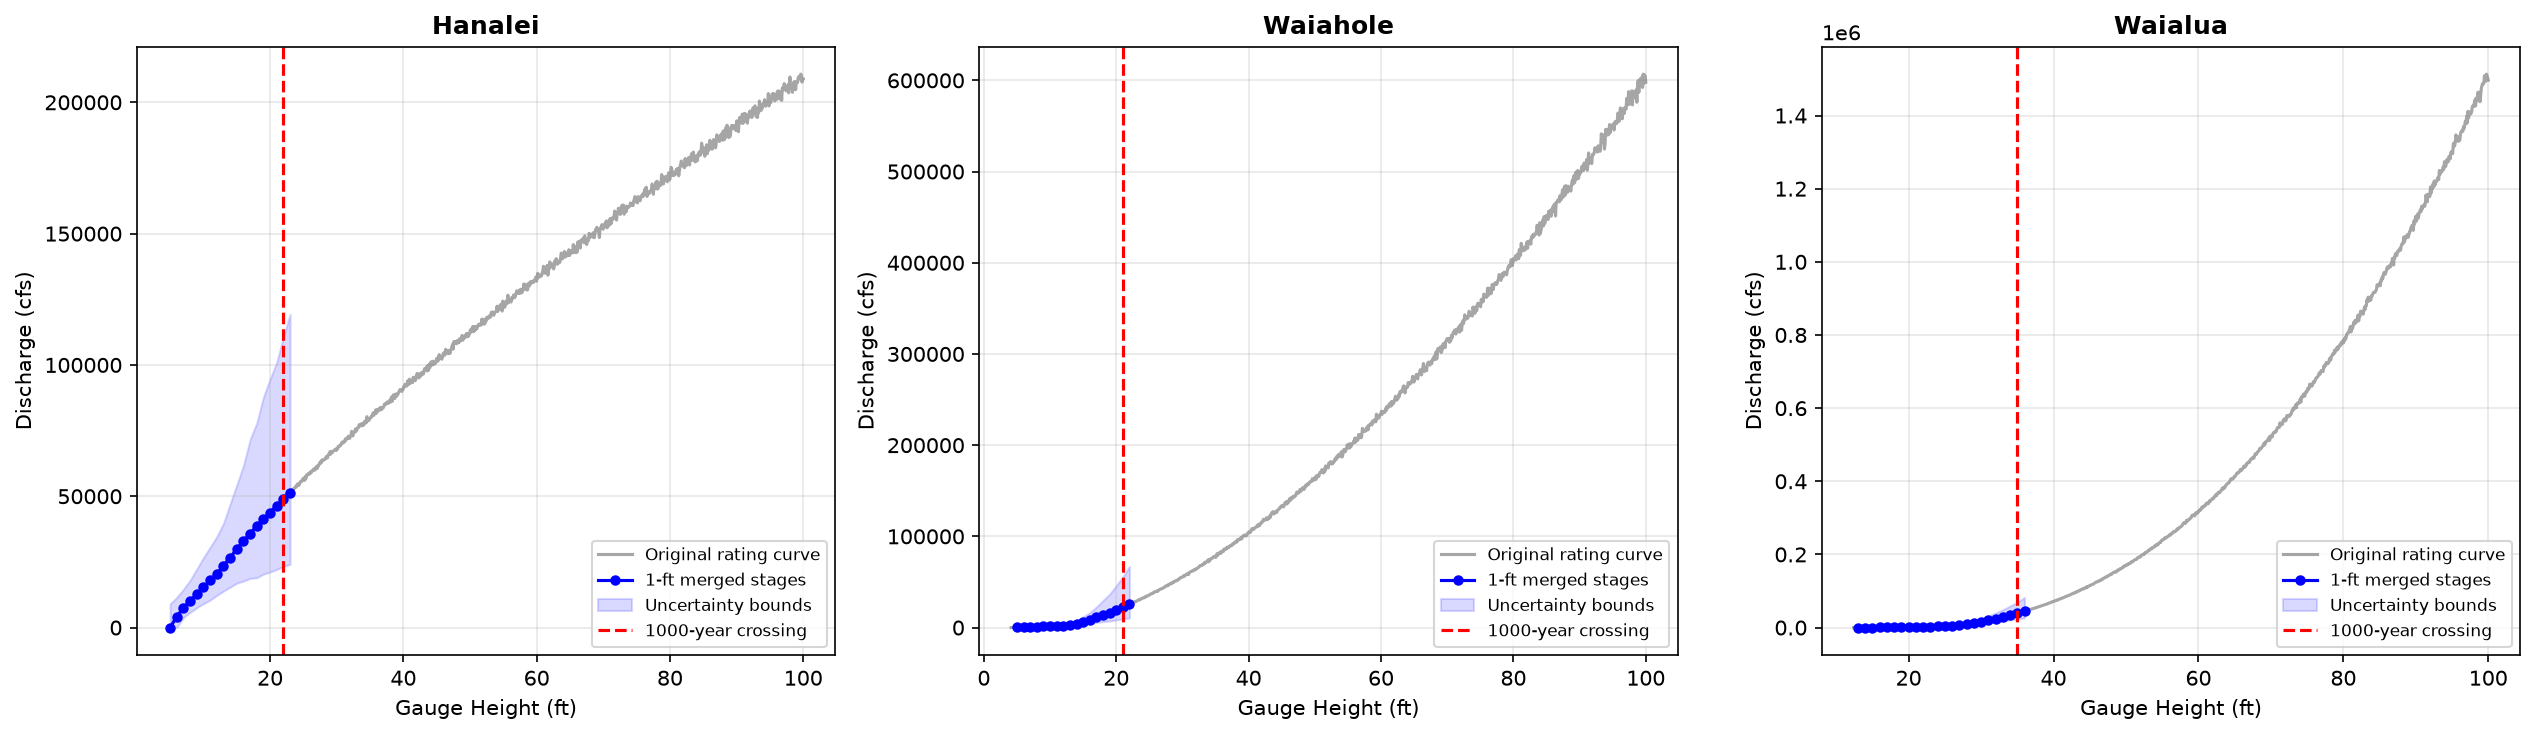

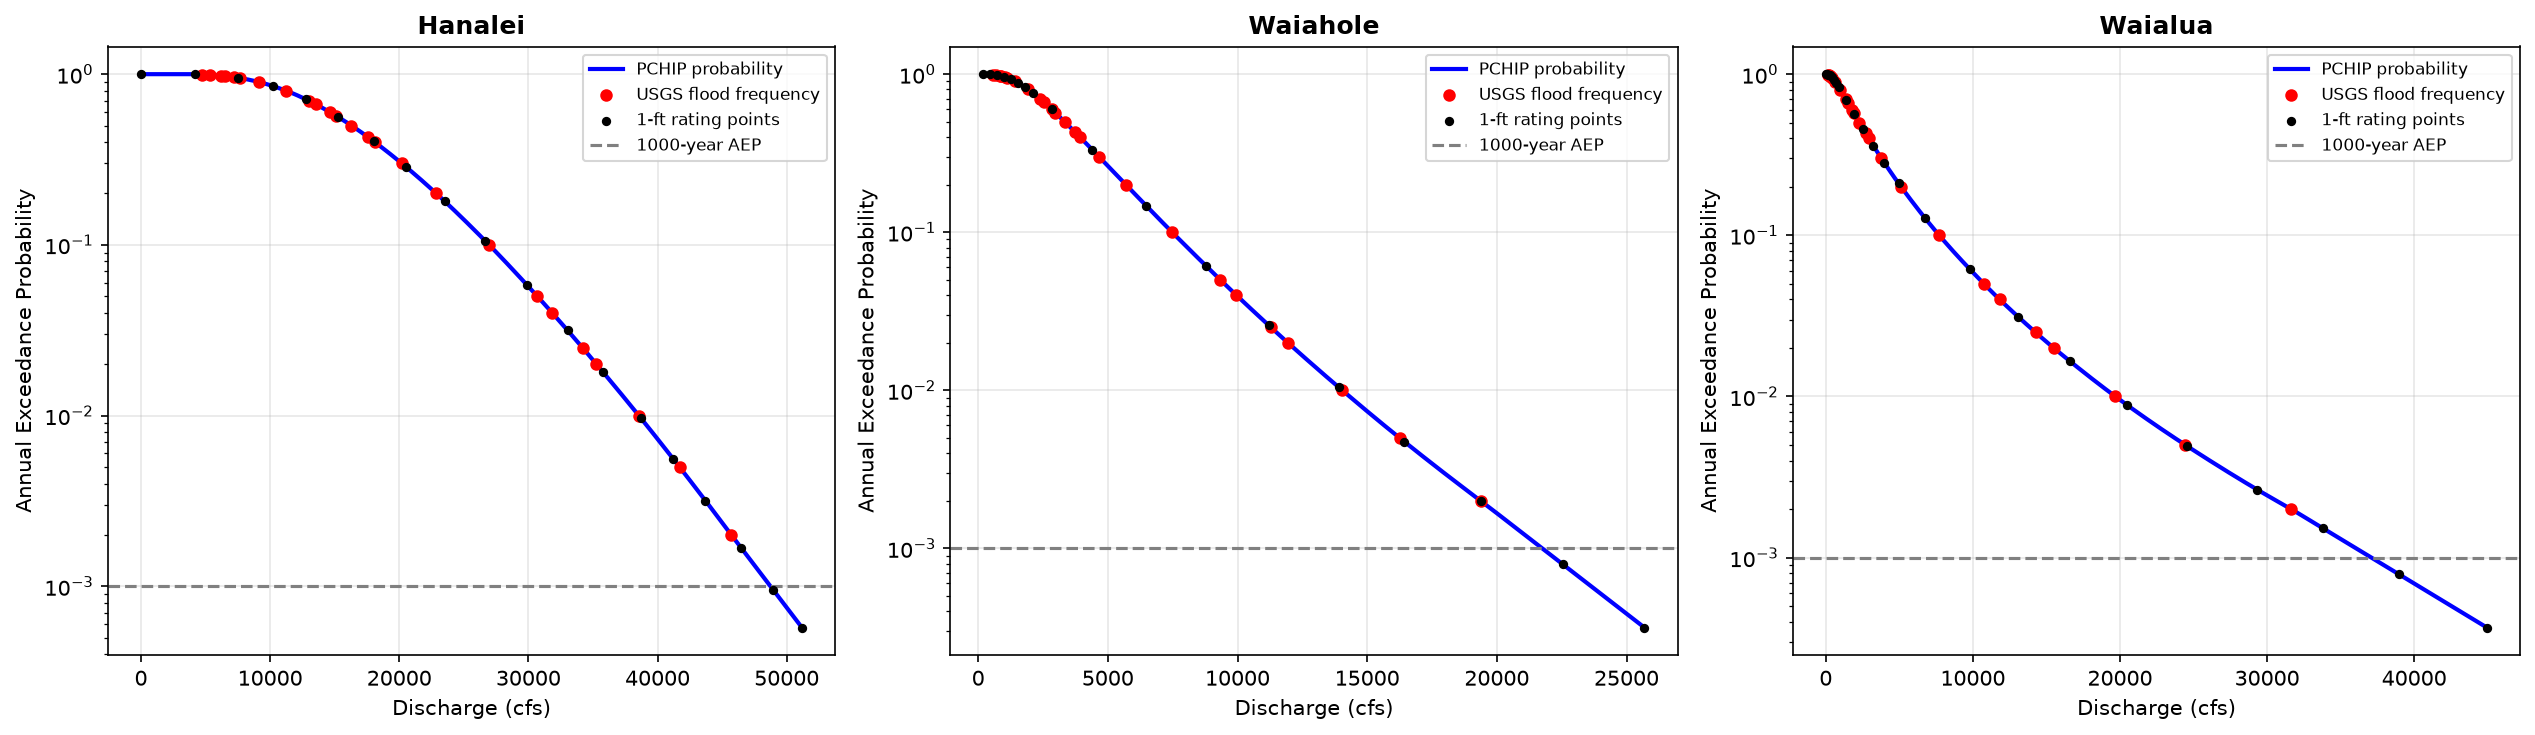

In [4]:

# ============================================================
# SETTINGS
# ============================================================

max_return_period = 1000
extra_stage_ft = 1

# ============================================================
# PROCESS ALL WATERSHEDS
# ============================================================

stage_probability_tables = {}
stage_probability_info = {}

for watershed, data in watershed_data.items():

    result, info = create_stage_probability_table(
        rating_df=data["rating_curve"],
        probability_df=data["probability"],
        max_return_period=max_return_period,
        extra_stage_ft=extra_stage_ft
    )

    stage_probability_tables[watershed] = result
    stage_probability_info[watershed] = info

    print(f"\n{'=' * 60}")
    print(watershed.upper())
    print(f"{'=' * 60}")

    print(
        f"{max_return_period}-year discharge: "
        f"{info['target_discharge_cfs']:,.1f} cfs"
    )
    print(f"First crossing stage: {info['target_stage_ft']} ft")
    print(f"Final cutoff stage: {info['cutoff_stage_ft']} ft")
    print(f"Number of 1-ft stages: {len(result)}")

    display(result)

# ============================================================
# SUMMARY
# ============================================================

summary = pd.DataFrame.from_dict(
    stage_probability_info,
    orient="index"
)

summary.index.name = "watershed"

print("\nFINAL SUMMARY")
display(summary)

# ============================================================
# PLOT 1: STAGE VS DISCHARGE
# ============================================================

fig_rating, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    dpi=150
)

for ax, (watershed, result) in zip(
    axes,
    stage_probability_tables.items()
):

    original = watershed_data[watershed]["rating_curve"]

    ax.plot(
        original["stage_ft"],
        original["median_cfs"],
        color="gray",
        linewidth=1.5,
        alpha=0.7,
        label="Original rating curve"
    )

    ax.plot(
        result["stage_ft"],
        result["median_cfs"],
        "o-",
        markersize=4,
        linewidth=1.5,
        color="blue",
        label="1-ft merged stages"
    )

    ax.fill_between(
        result["stage_ft"],
        result["lower_cfs"],
        result["upper_cfs"],
        color="blue",
        alpha=0.15,
        label="Uncertainty bounds"
    )

    info = stage_probability_info[watershed]

    if info["target_stage_ft"] is not None:
        ax.axvline(
            info["target_stage_ft"],
            color="red",
            linestyle="--",
            linewidth=1.5,
            label="1000-year crossing"
        )

    ax.set_title(watershed, fontweight="bold")
    ax.set_xlabel("Gauge Height (ft)")
    ax.set_ylabel("Discharge (cfs)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig_rating.tight_layout()
plt.show()

# ============================================================
# PLOT 2: DISCHARGE VS EXCEEDANCE PROBABILITY
# ============================================================

fig_probability, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    dpi=150
)

for ax, (watershed, result) in zip(
    axes,
    stage_probability_tables.items()
):

    probability = watershed_data[watershed]["probability"]

    q_dense = np.linspace(
        max(0, result["median_cfs"].min()),
        result["median_cfs"].max(),
        500
    )

    p_dense = predict_exceedance_probability(
        q_dense,
        probability
    )

    ax.plot(
        q_dense,
        p_dense,
        linewidth=2,
        color="blue",
        label="PCHIP probability"
    )

    ax.scatter(
        probability["discharge_cfs"],
        probability["EXC_Prob"],
        color="red",
        s=25,
        zorder=4,
        label="USGS flood frequency"
    )

    ax.scatter(
        result["median_cfs"],
        result["EXC_Prob"],
        color="black",
        s=12,
        zorder=5,
        label="1-ft rating points"
    )

    ax.axhline(
        1 / max_return_period,
        color="gray",
        linestyle="--",
        label=f"{max_return_period}-year AEP"
    )

    ax.set_yscale("log")
    ax.set_title(watershed, fontweight="bold")
    ax.set_xlabel("Discharge (cfs)")
    ax.set_ylabel("Annual Exceedance Probability")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig_probability.tight_layout()
plt.show()


In [6]:

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

output_dir = (
    script_dir /
    "SAVE_DATA" /
    "OBSERVED-stage-discharge-probability-results"
)

figure_dir = script_dir / "figures"

output_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# SAVE INDIVIDUAL WATERSHED TABLES
# ============================================================

for watershed, result in stage_probability_tables.items():

    output_file = (
        output_dir /
        f"{watershed}_stage_discharge_probability.csv"
    )

    result.to_csv(
        output_file,
        index=False
    )

    print(f"Saved: {output_file}")

# ============================================================
# SAVE SUMMARY TABLE
# ============================================================

summary_file = (
    output_dir /
    "watershed_probability_summary.csv"
)

summary.to_csv(summary_file)

print(f"Saved: {summary_file}")

# ============================================================
# SAVE FIGURES
# ============================================================

rating_figure_file = (
    figure_dir /
    "merged_stage_discharge_rating_curves.png"
)

probability_figure_file = (
    figure_dir /
    "merged_discharge_probability_curves.png"
)

fig_rating.savefig(
    rating_figure_file,
    dpi=300,
    bbox_inches="tight"
)

fig_probability.savefig(
    probability_figure_file,
    dpi=300,
    bbox_inches="tight"
)

print(f"Saved: {rating_figure_file}")
print(f"Saved: {probability_figure_file}")


Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\SAVE_DATA\OBSERVED-stage-discharge-probability-results\Hanalei_stage_discharge_probability.csv
Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\SAVE_DATA\OBSERVED-stage-discharge-probability-results\Waiahole_stage_discharge_probability.csv
Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\SAVE_DATA\OBSERVED-stage-discharge-probability-results\Waialua_stage_discharge_probability.csv
Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\SAVE_DATA\OBSERVED-stage-discharge-probability-results\watershed_probability_summary.csv
Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\merged_stage_discharge_rating_curves.png
Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\merged_discharge_probability_curves.png
